<a href="https://colab.research.google.com/github/jfbadarom/Fisica-com-Python/blob/main/Tarefa5_Jo%C3%A3oFelipe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip install ordpy#Instala a biblioteca ordpy na máquina

Importações das bibliotecas necessárias

In [10]:
import numpy as np
import ordpy
from matplotlib import pylab as plt


Definição do mapa logístico

In [11]:
def logistic(a=4, n=100000, x0=0.4):# Define a função do mapa logístico com o parametro de crescimento a(a=4 caso não for informado nenhum valor), o número de iterações n(n=100000 caso não for informado nenhum valor) e a posição inicial x0(x0=0.4 caso não for informado nenhum valor).
    x = np.zeros(n) # Array de tamanho n com zeros em todos os espaços
    x[0] = x0 #Substituí o a primeira posiçaõ do vetor pelo valor indicado para a posição inicial do mapa logístico
    for i in range(n-1): # Itera 1 até n-1 já que a primeira posição do vetor já foi definida
        x[i+1] = a*x[i]*(1-x[i])# Passos do mapa logístico
    return(x)

In [12]:
time_series = [logistic(a) for a in [3.05, 3.55, 4]]# Faz uma lista de evoluções do mapa logístico variando os valores do parametro de crescimento a=[3.05, 3.55, 4]
time_series += [np.random.normal(size=100000)] # Soma a lista uma lista de valores aleatórios sorteados a partir da distribuição gaussiana normal com tamanho 100000

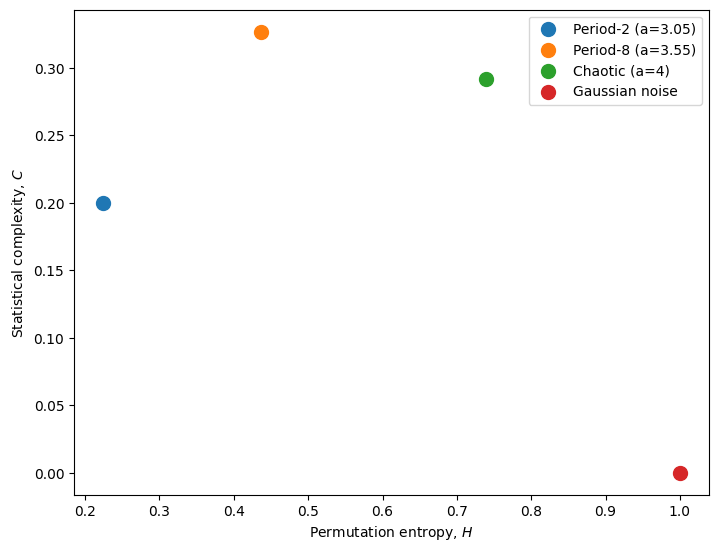

In [13]:
HC = [ordpy.complexity_entropy(series, dx=4) for series in time_series] # Cria uma lista na qual cada item carrega o par complexidade e entropia para cada uma das séries temporais na lista time_series construída antes

f, ax = plt.subplots(figsize=(8.19, 6.3)) # Cria a variável da figura

for HC_, label_ in zip(HC, ['Period-2 (a=3.05)',
                            'Period-8 (a=3.55)',
                            'Chaotic (a=4)',
                            'Gaussian noise']): # Roda a iteração em HC_ para a lista HC(complexidade e entropia das séries) e label_(label para cada um das séries)
    ax.scatter(*HC_, label=label_, s=100) #Usa o par de pontos para plotar um scatter

ax.set_xlabel('Permutation entropy, $H$')# Legenda do eixo X
ax.set_ylabel('Statistical complexity, $C$')# Legenda do eixo Y

ax.legend()# Coloca a legenda no gráfico indicando cada label


Neste gráfico de Entropia e Complexidade o que podemos perceber é que  quando aumentaos o parametro de crescimento tanto a complexidade quanto a entropia do série temporal aumenta porém quando a série temporal do mapa logístico entra no regime caótico a=4, a complexidade dele diminui em relação mas a entropia aumenta, o que significa que para a=4 o sistema se torna mais aleatório e consequentemente menos complexo. E o ponto vermelho que descreve um ruído gaussiano a não tem complexidade pois suas posições saem de uma distribuição gaussiana mas tem entropia máxima pois como os pontos são aleatórios a partir da distribuição sua entropia tende a ser máxima. Mostra também uma diferença entre o caótico e o aleatório tanto em complexidade quanto em entropia.

In [14]:
ordpy.complexity_entropy((logistic()), dx=4)

(np.float64(0.7387519146337447), np.float64(0.29181531164527763))